# Historical Retention Analysis — Subscription Customers

**Objective.** Describe how customers have historically retained, as input to estimating the expected 24-month margin of a
new customer with given features (channel, plan, discount).

**Scope.** Descriptive analysis of the customer snapshot only. No models and no forecasts beyond observed tenure.

**Data.** Customer-level snapshot taken at the end of month 24. Customers signed up between months 0 and 23. Customers still
active at the snapshot are right-censored: we know they've lasted *at least* their observed tenure.

---

### Summary of findings

1. **Retention drops steeply early, then flattens.** About 76% of customers remain after month 1, 55% after month 3, 41% after month 6
   and 25% after month 12. Nearly half (48%) of first-year churn happens by month 2.
2. **No cohort trend.** Month-1/3/6/12 retention is flat across signup cohorts, and differences between cohorts are within sampling noise.
   There's no evidence that retention is improving or deteriorating.
3. **Reporting method matters a lot.** A snapshot churn rate (dividing by all customers) understates 12-month retention by about
   half (13.5% vs. 24.7%) and 24-month margin per customer by about 25% ($72 vs. $96), because it counts recent signups as churned.
4. **Month-over-month retention rises from 76% to about 92% by month 6, then plateaus.** The same pattern appears inside every segment,
   which is consistent with high-risk customers leaving early (a change in who remains) rather than customers becoming more engaged.
5. **Segments differ materially.** Referral customers retain best (33% at month 12 vs. 20% for paid social). Discounted signups
   retain worst (17.5% vs. 28%). Historical 24-month margin per customer ranges from about $79 (discounted) to about $124 (referral).
6. **Data beyond about month 18 is thin.** Only 147 customers can be observed at month 24 (95% CI for retention: 6%–16%). Long-tenure
   estimates need a model (next analysis).

In [1]:
import sys
sys.path.insert(0, "../src")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from retention import status_matrix, cohort_triangle, retention_curve
from ltv import ltv

SNAPSHOT_MONTH = 24
HORIZON = 24

customers = pd.read_csv("../data/customers.csv")
customers["window"] = SNAPSHOT_MONTH - customers["signup_month"]
customers.head()

,customer_id,signup_month,channel,plan,discount_at_signup,months_observed,churned,monthly_margin,window
0,0,2,referral,monthly,0,1,1,14.0,22
1,1,18,paid_social,annual,0,6,0,11.0,6
2,2,15,referral,monthly,1,8,1,14.0,9
3,3,10,search,annual,1,5,1,11.0,14
4,4,10,paid_social,annual,0,4,1,11.0,14


## 1. Data checks

Before computing anything: is the table complete, unique, and internally consistent?

In [2]:
checks = {
    "rows": len(customers),
    "unique customer_id": customers.customer_id.nunique(),
    "missing values (all columns)": int(customers.isna().sum().sum()),
    "months_observed within [1, window]": bool(customers.months_observed.between(1, customers.window).all()),
    "active customers observed for full window": bool(
        (customers.loc[customers.churned == 0, "months_observed"] == customers.loc[customers.churned == 0, "window"]).all()),
    "share still active at snapshot": round(1 - customers.churned.mean(), 3),
}
pd.Series(checks, name="value").to_frame()

,value
rows,4000
unique customer_id,4000
missing values (all columns),0
"months_observed within [1, window]",True
active customers observed for full window,True
share still active at snapshot,0.298


All checks pass. 30% of customers are still active, so **censoring is substantial** and any metric must account for it.

### Signup volume and mix over time
Comparing cohorts is only meaningful if they're similar. If the acquisition mix shifted (for example toward paid social), changes in
blended retention could reflect mix rather than product.

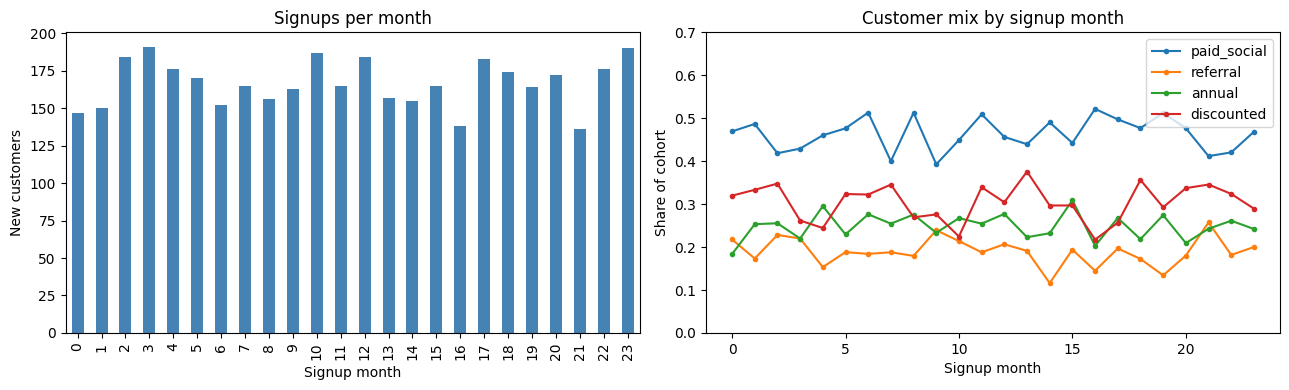

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

customers.groupby("signup_month").size().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Signups per month")
axes[0].set_xlabel("Signup month")
axes[0].set_ylabel("New customers")

mix = (customers.assign(discounted=customers.discount_at_signup, annual=customers.plan.eq("annual"),
                        paid_social=customers.channel.eq("paid_social"), referral=customers.channel.eq("referral"))
       .groupby("signup_month")[["paid_social", "referral", "annual", "discounted"]].mean())
mix.plot(ax=axes[1], marker="o", ms=3)
axes[1].set_title("Customer mix by signup month")
axes[1].set_xlabel("Signup month")
axes[1].set_ylabel("Share of cohort")
axes[1].set_ylim(0, 0.7)
plt.tight_layout()
plt.show()

**Takeaway:** volume is steady (about 165 signups per month) and the mix of channel, plan and discount is stable across cohorts, so differences
between cohorts can be read as retention differences, not mix differences.

## 2. Metric definition

**Retention at tenure k** = share of customers still active *k* months after signup.

A customer can only contribute to tenure k if they've been observable for k months (`window = 24 − signup_month ≥ k`).
Customers who haven't reached tenure k are **excluded**, not counted as churned. Every metric below uses this
censoring-aware definition unless labelled "snapshot".

## 3. Cohort retention triangle

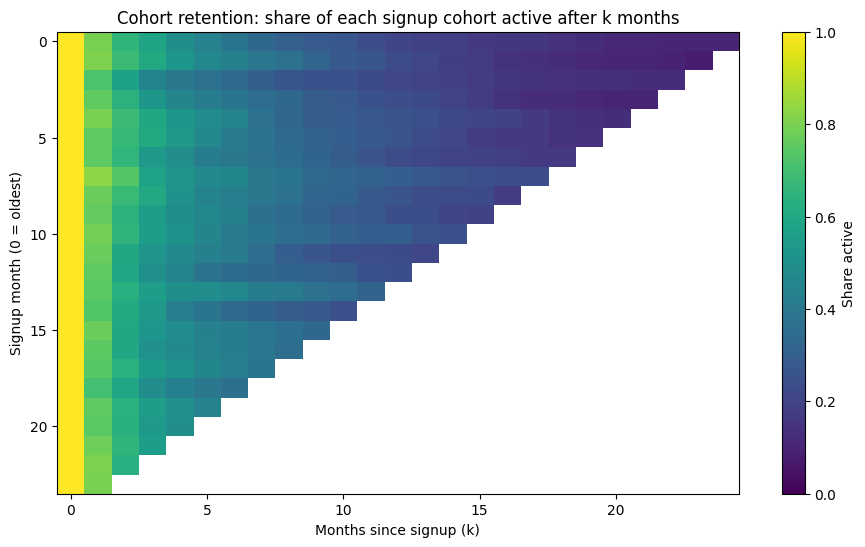

signup_month,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
1,0.80,0.81,0.72,0.75,0.80,0.75,0.75,0.82,0.78,0.76,...,0.73,0.78,0.75,0.74,0.70,0.76,0.74,0.78,0.8,0.8
3,0.59,0.61,0.45,0.53,0.60,0.61,0.54,0.58,0.60,0.56,...,0.54,0.53,0.51,0.55,0.49,0.56,0.54,0.56,NaN,NaN
6,0.39,0.44,0.34,0.39,0.45,0.42,0.40,0.46,0.43,0.44,...,0.34,0.42,0.42,0.43,0.37,NaN,NaN,NaN,NaN,NaN
12,0.21,0.23,0.21,0.24,0.26,0.26,0.23,0.30,0.26,0.24,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
triangle = cohort_triangle(customers, SNAPSHOT_MONTH, HORIZON)

fig, ax = plt.subplots(figsize=(11, 6))
im = ax.imshow(triangle.values, aspect="auto", cmap="viridis", vmin=0, vmax=1)
ax.set_title("Cohort retention: share of each signup cohort active after k months")
ax.set_xlabel("Months since signup (k)")
ax.set_ylabel("Signup month (0 = oldest)")
fig.colorbar(im, ax=ax, label="Share active")
plt.show()

triangle[[1, 3, 6, 12]].round(2).T

**Takeaway:** all cohorts share the same shape, with a steep drop over months 1–3 and a slow decline after that. The blank lower-right region is
cohorts that haven't yet reached that tenure.

### Is retention changing across cohorts?

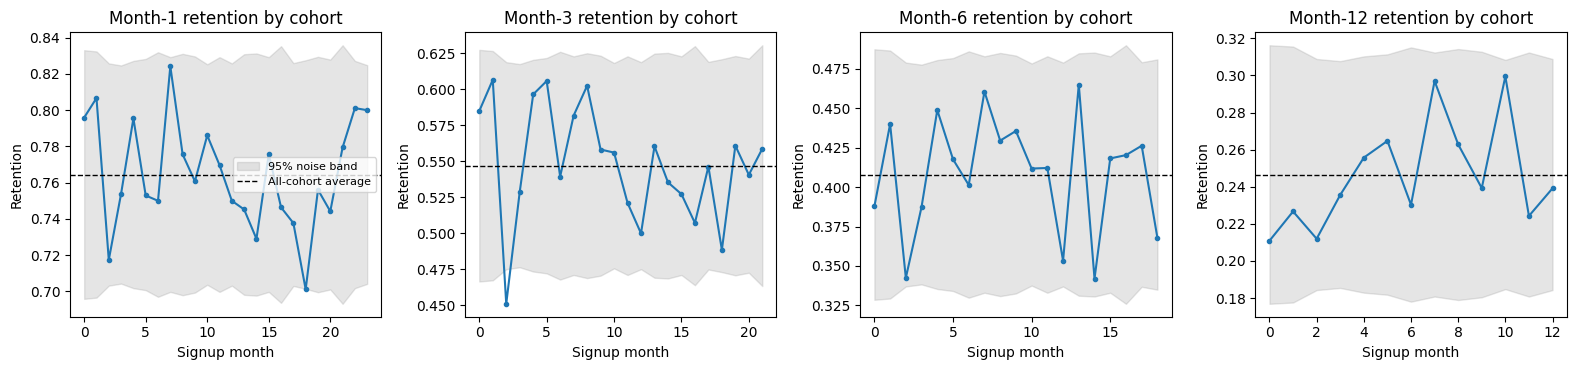

In [5]:
cohort_size = customers.groupby("signup_month").size()

fig, axes = plt.subplots(1, 4, figsize=(16, 3.8), sharey=False)
for ax, k in zip(axes, [1, 3, 6, 12]):
    r = triangle[k].dropna()
    n = cohort_size[r.index]
    pooled = (r * n).sum() / n.sum()
    band = 1.96 * np.sqrt(pooled * (1 - pooled) / n)
    ax.fill_between(r.index, pooled - band, pooled + band, color="grey", alpha=0.2, label="95% noise band")
    ax.plot(r.index, r.values, marker="o", ms=3)
    ax.axhline(pooled, color="black", lw=1, ls="--", label="All-cohort average")
    ax.set_title(f"Month-{k} retention by cohort")
    ax.set_xlabel("Signup month")
    ax.set_ylabel("Retention")
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Takeaway:** 76 of 78 cohort points fall inside the 95% noise band (about what chance alone would produce), and there's no upward or downward drift.
**Retention has been stable over the past two years.** This also supports pooling cohorts into one blended curve.

## 4. Blended retention curve

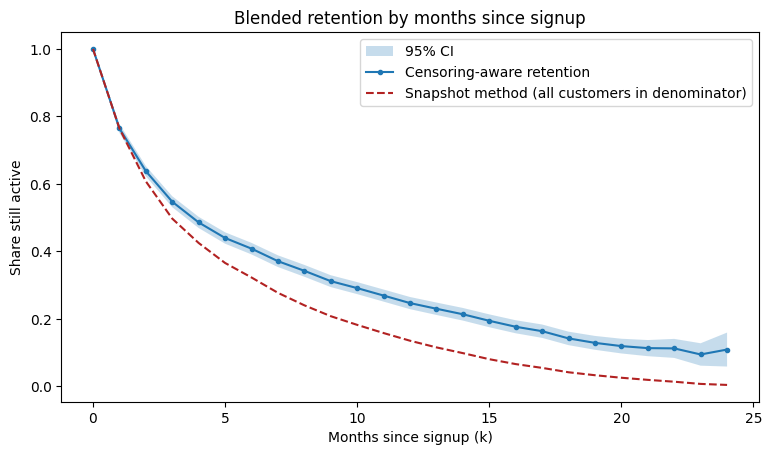

,n_observable,retention,ci_low,ci_high,snapshot_method
k,,,,,
1,4000,0.764,0.751,0.778,0.764
3,3634,0.547,0.531,0.563,0.497
6,3162,0.408,0.391,0.425,0.322
12,2190,0.247,0.229,0.265,0.135
18,1170,0.142,0.122,0.162,0.042
24,147,0.109,0.058,0.159,0.004


In [6]:
curve = retention_curve(customers, SNAPSHOT_MONTH, HORIZON, method="pooled")
snapshot = retention_curve(customers, SNAPSHOT_MONTH, HORIZON, method="snapshot")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.fill_between(curve.index, curve.ci_low, curve.ci_high, alpha=0.25, label="95% CI")
ax.plot(curve.index, curve.retention, marker="o", ms=3, label="Censoring-aware retention")
ax.plot(snapshot.index, snapshot.retention, ls="--", color="firebrick", label="Snapshot method (all customers in denominator)")
ax.set_title("Blended retention by months since signup")
ax.set_xlabel("Months since signup (k)")
ax.set_ylabel("Share still active")
ax.legend()
plt.show()

summary = curve.loc[[1, 3, 6, 12, 18, 24], ["n_observable", "retention", "ci_low", "ci_high"]].copy()
summary["snapshot_method"] = snapshot.retention
summary.round(3)

**Takeaway:** retention is 76% / 55% / 41% / 25% at months 1 / 3 / 6 / 12. The snapshot method falls further behind as tenure grows
(13.5% vs. 24.7% at month 12) because it counts customers who simply haven't reached that tenure as churned. Beyond month 18 the sample
shrinks quickly (147 customers at month 24) and the confidence interval widens to ±5 points.

### Impact on unit economics
24-month margin per customer = Σ retention(k) × monthly margin ÷ 1.01^k, using the observed curve (not a forecast).

In [7]:
margin = customers.monthly_margin.mean()
unit_econ = pd.DataFrame({
    "24m margin per customer": [ltv(curve.retention, margin), ltv(snapshot.retention, margin)],
}, index=["Censoring-aware", "Snapshot method"])
unit_econ["difference"] = unit_econ.iloc[:, 0] / unit_econ.iloc[0, 0] - 1
unit_econ.round(2)

,24m margin per customer,difference
Censoring-aware,96.42,0.00
Snapshot method,72.40,-0.25


**Takeaway:** the snapshot method would understate customer value by about 25% ($72 vs. $96). If acquisition spend is capped at customer value,
this would block profitable acquisition in the $72–$96 cost range.

## 5. Month-over-month retention by tenure

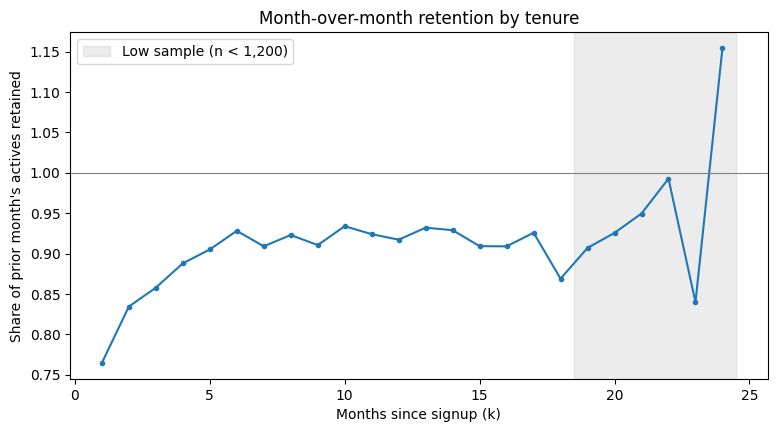

k,1,2,3,4,6,9,12
mom_retention,0.764,0.834,0.858,0.888,0.928,0.91,0.917


In [8]:
mom = (curve.retention / curve.retention.shift(1)).rename("mom_retention")

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(mom.index, mom.values, marker="o", ms=3)
ax.axhline(1, color="grey", lw=0.8)
ax.axvspan(18.5, 24.5, color="grey", alpha=0.15, label="Low sample (n < 1,200)")
ax.set_title("Month-over-month retention by tenure")
ax.set_xlabel("Months since signup (k)")
ax.set_ylabel("Share of prior month's actives retained")
ax.legend()
plt.show()

mom.loc[[1, 2, 3, 4, 6, 9, 12]].round(3).to_frame().T

**Takeaway:** month-over-month retention climbs from 76% in month 1 to about 92% by month 6, then plateaus. After month 18 the series is noisy and
includes values above 100%. This happens because different sets of cohorts make up the numerator and the denominator at those tenures. It isn't real.

**Interpretation.** A rising month-over-month curve has two possible explanations:
- **Behavior:** customers become more engaged the longer they stay.
- **Composition:** customers differ in their underlying risk, high-risk customers leave first, and the remaining base is lower-risk.

These two can't be told apart with aggregate data. One check: if the rise were driven by the *observed* segments (for example
paid-social customers leaving early), it would disappear within segments.

In [9]:
rows = {}
for col in ["channel", "plan", "discount_at_signup"]:
    for value, grp in customers.groupby(col):
        r = retention_curve(grp, SNAPSHOT_MONTH, HORIZON).retention
        m = r / r.shift(1)
        rows[(col, value)] = {"n": len(grp), "MoM month 1": m[1], "MoM month 3": m[3], "MoM month 6": m[6]}
pd.DataFrame(rows).T.round(3)

n  MoM month 1  MoM month 3  MoM month 6
channel            paid_social  1852.0        0.713        0.855        0.919
                   referral      760.0        0.858        0.872        0.958
                   search       1388.0        0.782        0.852        0.917
plan               annual        996.0        0.843        0.884        0.946
                   monthly      3004.0        0.738        0.847        0.921
discount_at_signup 0            2786.0        0.790        0.858        0.931
                   1            1214.0        0.706        0.855        0.919

**Takeaway:** the rise appears inside **every** segment (for example paid social goes from 71% to 92%, and referral from 86% to 96%). Observed segments don't explain it.
It's most likely variation in risk *between individual customers* that our features don't capture, though a real increase in engagement can't be ruled out
from this data alone. **Practical implication:** don't credit the rising curve to onboarding or the product without a controlled comparison,
and don't project future churn from early months at a constant rate, because that would sharply understate long-run retention.

## 6. Retention by segment

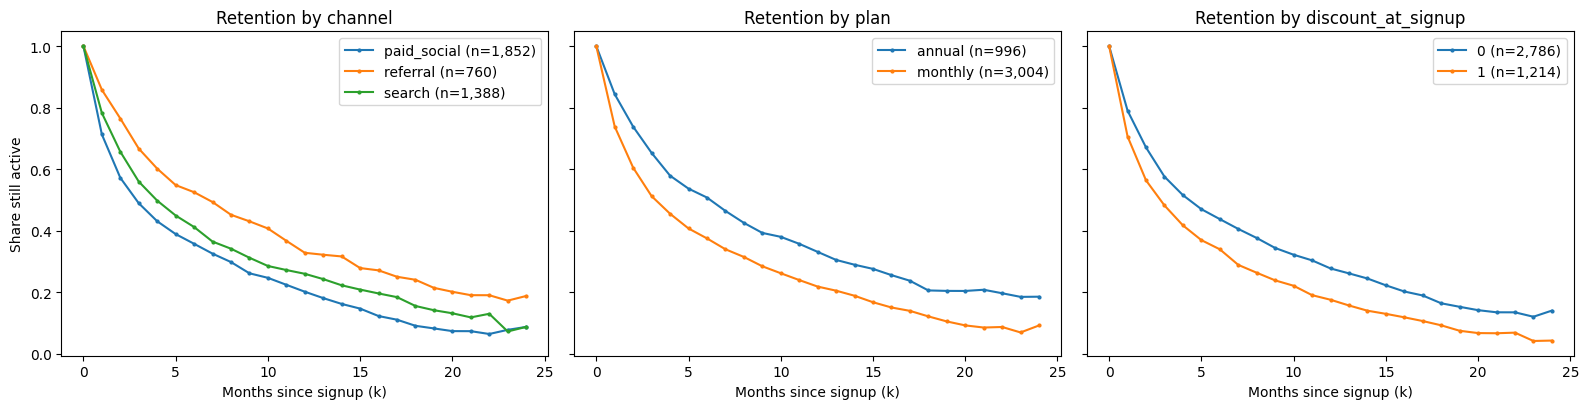

customers     M1     M3     M6    M12  \
segment            value                                                
channel            paid_social       1852  0.713  0.489  0.357  0.201   
                   referral           760  0.858  0.667  0.525  0.328   
                   search            1388  0.782  0.559  0.412  0.260   
plan               annual             996  0.843  0.653  0.508  0.331   
                   monthly           3004  0.738  0.512  0.375  0.218   
discount_at_signup 0                 2786  0.790  0.575  0.437  0.277   
                   1                 1214  0.706  0.482  0.339  0.175   

                                monthly margin  24m margin per customer  
segment            value                                                 
channel            paid_social          13.260                   83.266  
                   referral             13.258                  123.626  
                   search               13.241                   98.595  
plan               annual               11.000                   99.381  
                   monthly              14.000                   93.798  
discount_at_signup 0                    13.248                  104.100  
                   1                    13.264                   78.820

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
seg_rows = []
for ax, col in zip(axes, ["channel", "plan", "discount_at_signup"]):
    for value, grp in customers.groupby(col):
        r = retention_curve(grp, SNAPSHOT_MONTH, HORIZON)
        ax.plot(r.index, r.retention, marker="o", ms=2, label=f"{value} (n={len(grp):,})")
        seg_rows.append({
            "segment": col, "value": value, "customers": len(grp),
            "M1": r.retention[1], "M3": r.retention[3], "M6": r.retention[6], "M12": r.retention[12],
            "monthly margin": grp.monthly_margin.mean(),
            "24m margin per customer": ltv(r.retention, grp.monthly_margin.mean()),
        })
    ax.set_title(f"Retention by {col}")
    ax.set_xlabel("Months since signup (k)")
    ax.legend()
axes[0].set_ylabel("Share still active")
plt.tight_layout()
plt.show()

segments = pd.DataFrame(seg_rows).set_index(["segment", "value"])
segments.round(3)

**Takeaway:**
- **Channel:** referral retains best (33% at month 12) and paid social worst (20%). Paid social is the largest channel (46% of signups) and
  has about one-third lower 24-month margin per customer than referral ($83 vs. $124).
- **Plan:** annual customers retain much better (33% vs. 22% at month 12), which roughly offsets their lower monthly margin. 24-month value
  ends up similar ($99 vs. $94).
- **Discount:** discounted signups retain worse at every tenure and are worth about 24% less ($79 vs. $104). Whether the discount *causes*
  this or just attracts more price-sensitive customers can't be determined from this data.

**Are these segment effects independent?** If segments overlap (for example most discounts going to paid social), the
differences above would double-count each other.

In [11]:
pd.concat({
    "discount rate by channel": customers.groupby("channel").discount_at_signup.mean(),
    "annual share by channel": customers.groupby("channel").plan.apply(lambda s: s.eq("annual").mean()),
}, axis=1).round(3)

,discount rate by channel,annual share by channel
channel,,
paid_social,0.308,0.247
referral,0.295,0.247
search,0.302,0.253


**Takeaway:** discount and plan rates are similar across channels, so the segment differences are roughly independent of each other. A joint
model (next step) will confirm this while accounting for censoring properly.

## 7. Limitations

- **Descriptive, not causal.** Segment differences show who retains better, not what would happen if we changed channel spend or removed the discount.
- **Thin long-tenure data.** Estimates beyond month 18 rest on a small number of cohorts, and month 24 rests on a single cohort.
- **Partial use of censored data.** The cohort-average method drops customers at tenures they haven't reached, even though their survival up
  to that point is informative. That makes long-tenure estimates noisier than necessary.
- **No forecast beyond month 24.** This analysis can't say anything about tenure the data hasn't reached.

## 8. Next steps

1. **Kaplan-Meier survival curves:** use every customer's full observed history to get tighter long-tenure estimates, and formally test segment
   differences (log-rank).
2. **Cox regression:** estimate each segment's effect while holding the others constant.
3. **Parametric models (Weibull, sBG):** project retention beyond observed tenure, and test whether models fitted on early months recover
   later retention.
